# Lab Task 3 — Mathematical Operations (REAL datasets)

## Datasets used (not random)
| File | Source |
|------|--------|
| `dataset/parking_lot_PKLot.jpg` | **PKLot** real parking-lot dataset (UFPR) |
| `dataset/forest_area.jpg` | Real forest photo for Task 6 |
| NumPy gradient / checkerboard / RGB | Required synthetic images |

Outputs → `Output/Lab 3/`


## 0. Setup


In [3]:
import sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install","-q","opencv-python-headless","matplotlib","numpy"])
import cv2, numpy as np, matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
for c in [NOTEBOOK_DIR, NOTEBOOK_DIR/"Lab Tasks"/"Lab task 3", Path(r"C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 3")]:
    if (c/"dataset"/"parking_lot_PKLot.jpg").exists():
        NOTEBOOK_DIR = c; break
ROOT = NOTEBOOK_DIR
for _ in range(6):
    if (ROOT/"Output").exists(): break
    ROOT = ROOT.parent
OUT = ROOT/"Output"/"Lab 3"; OUT.mkdir(parents=True, exist_ok=True)
DS = NOTEBOOK_DIR/"dataset"
PARKING = DS/"parking_lot_PKLot.jpg"
FOREST = DS/"forest_area.jpg"
print("PKLot parking:", PARKING, PARKING.exists())
print("Forest:", FOREST, FOREST.exists())
print("Files:", [p.name for p in DS.iterdir()] if DS.exists() else None)


PKLot parking: C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 3\dataset\parking_lot_PKLot.jpg True
Forest: C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Lab Tasks\Lab task 3\dataset\forest_area.jpg True
Files: ['forest_area.jpg', 'numpy_checkerboard.jpg', 'numpy_gradient.jpg', 'numpy_synthetic_rgb.jpg', 'parking_lot_PKLot.jpg', 'README.txt', 'SOURCE.txt', 'uploaded_photo.jpg']


## 1. Load & show REAL datasets


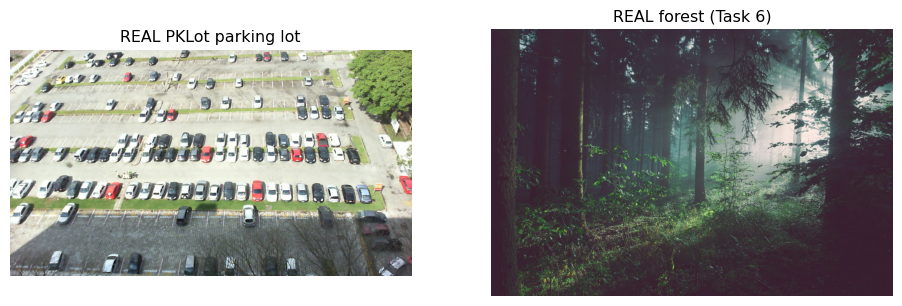

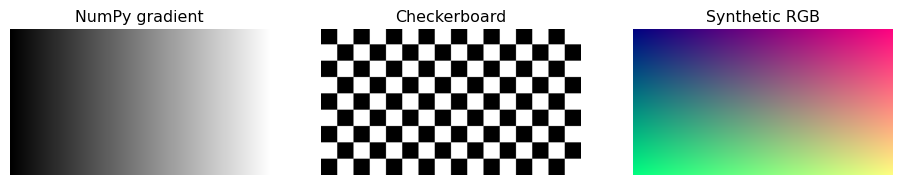

In [5]:
def ensure_dir(p):
    Path(p).mkdir(parents=True, exist_ok=True); return Path(p)
def to_rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim==3 else im
def save_bgr(path, im):
    ensure_dir(Path(path).parent); cv2.imwrite(str(path), im)
def save_fig(path):
    ensure_dir(Path(path).parent); plt.tight_layout(); plt.savefig(path, dpi=140, bbox_inches="tight"); plt.close()
def show_pair(a,b,t1,t2,save_path=None):
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    ax[0].imshow(to_rgb(a)); ax[0].set_title(t1); ax[0].axis("off")
    ax[1].imshow(to_rgb(b)); ax[1].set_title(t2); ax[1].axis("off")
    plt.tight_layout(); plt.show()
    if save_path:
        fig,ax=plt.subplots(1,2,figsize=(10,4))
        ax[0].imshow(to_rgb(a)); ax[0].set_title(t1); ax[0].axis("off")
        ax[1].imshow(to_rgb(b)); ax[1].set_title(t2); ax[1].axis("off")
        save_fig(save_path)

img=cv2.imread(str(PARKING)); forest_img=cv2.imread(str(FOREST))
assert img is not None, "Missing PKLot dataset"
assert forest_img is not None, "Missing forest dataset"
plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(to_rgb(img)); plt.title("REAL PKLot parking lot"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(to_rgb(forest_img)); plt.title("REAL forest (Task 6)"); plt.axis("off")
plt.show()

work=cv2.resize(img,(640,360)); h,w=work.shape[:2]
grad=np.tile(np.linspace(0,255,w,dtype=np.float32),(h,1))
np_img=cv2.cvtColor(grad.astype(np.uint8),cv2.COLOR_GRAY2BGR)
tile=40; yy,xx=np.indices((h,w))
checker=cv2.cvtColor(((((yy//tile)+(xx//tile))%2)*255).astype(np.uint8),cv2.COLOR_GRAY2BGR)
syn=np.zeros((h,w,3),np.uint8); syn[:,:,2]=np.linspace(0,255,w,np.uint8); syn[:,:,1]=np.linspace(0,255,h,np.uint8)[:,None]; syn[:,:,0]=128
src=ensure_dir(OUT/"_sources")
save_bgr(src/"parking_resized.jpg", work)
for n,im in [("gradient",np_img),("checkerboard",checker),("synthetic_rgb",syn)]:
    save_bgr(src/f"{n}.jpg", im)
plt.figure(figsize=(12,3))
plt.subplot(1,3,1); plt.imshow(to_rgb(np_img)); plt.title("NumPy gradient"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(to_rgb(checker)); plt.title("Checkerboard"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(to_rgb(syn)); plt.title("Synthetic RGB"); plt.axis("off")
plt.show()


## Task 1 — Addition


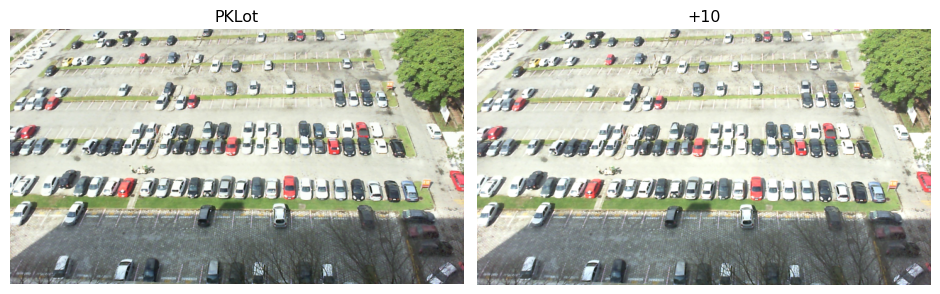

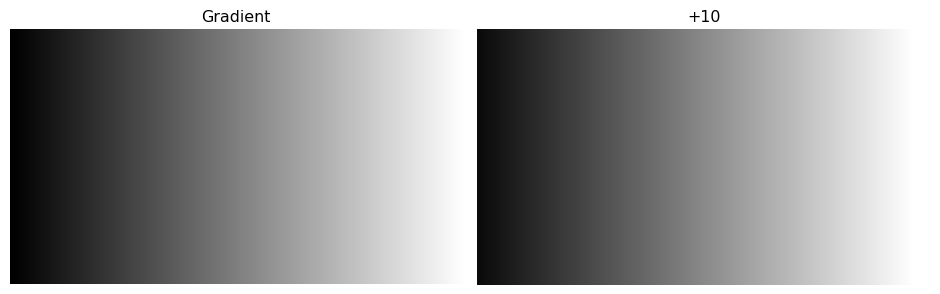

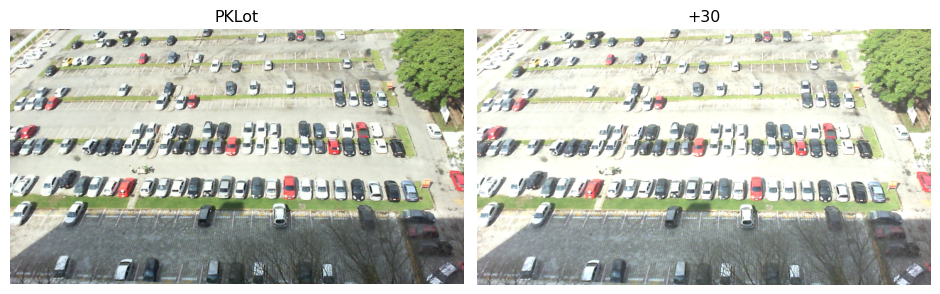

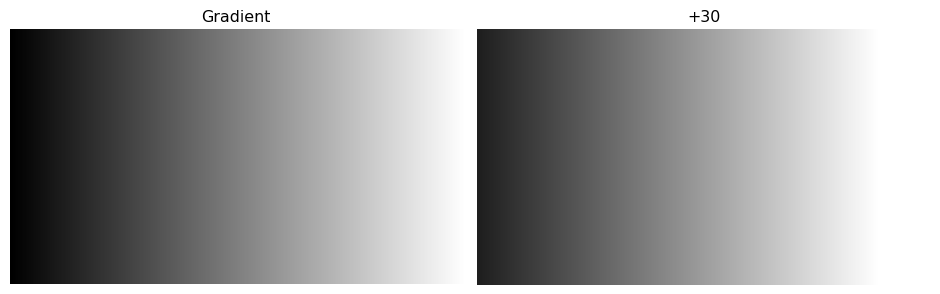

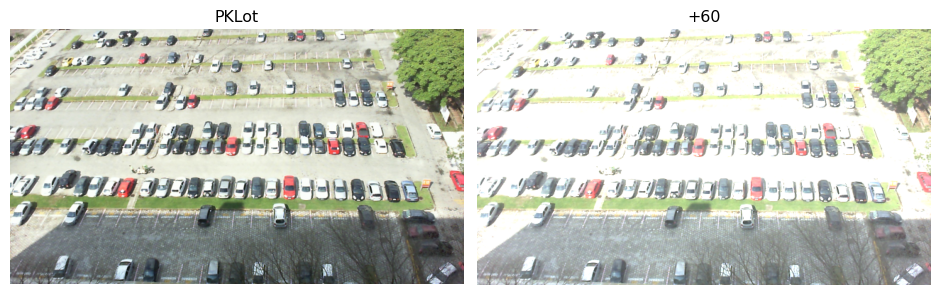

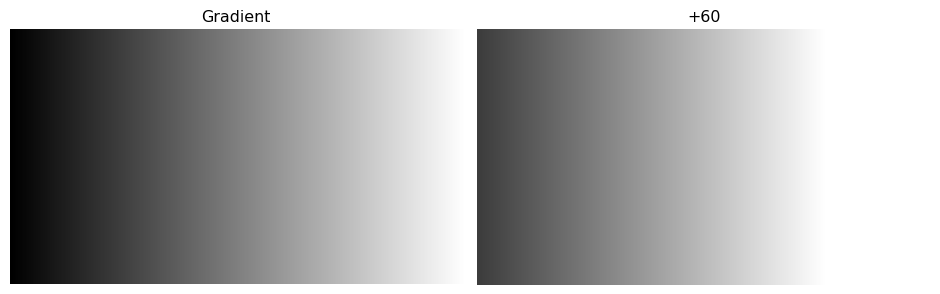

In [7]:
t1=ensure_dir(OUT/"Task 1"); notes=["Addition on PKLot + NumPy.\n"]
for c in (10,30,60):
    a=cv2.add(work,np.full_like(work,c)); b=cv2.add(np_img,np.full_like(np_img,c))
    show_pair(work,a,"PKLot",f"+{c}",t1/f"parking_add_{c}.png")
    show_pair(np_img,b,"Gradient",f"+{c}",t1/f"numpy_add_{c}.png")
    save_bgr(t1/f"parking_add_{c}.jpg",a); save_bgr(t1/f"numpy_add_{c}.jpg",b)
    notes.append(f"c={c}: {work.mean():.1f}->{a.mean():.1f}")
(t1/"observation.txt").write_text("\n".join(notes)+"\n",encoding="utf-8")


## Task 2 — Subtraction


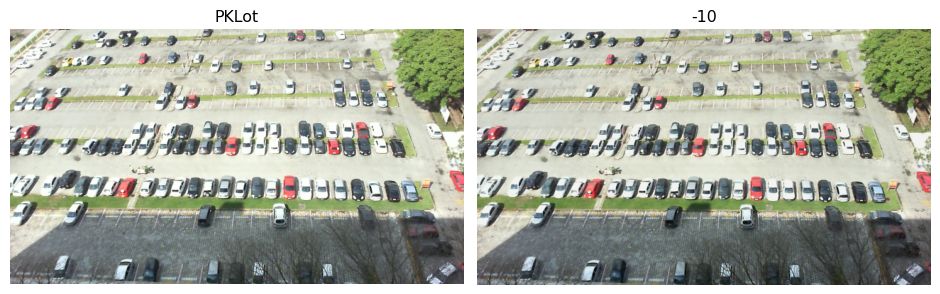

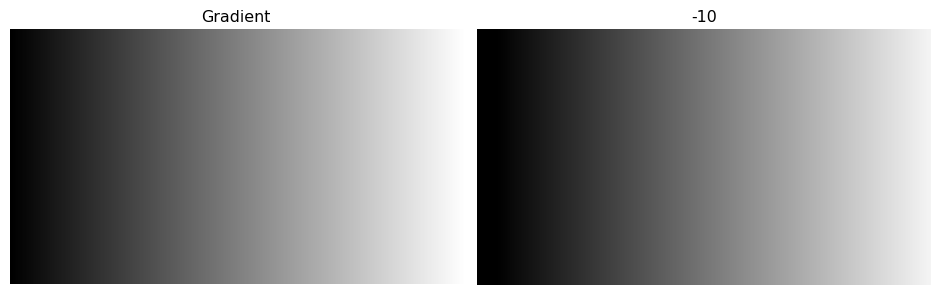

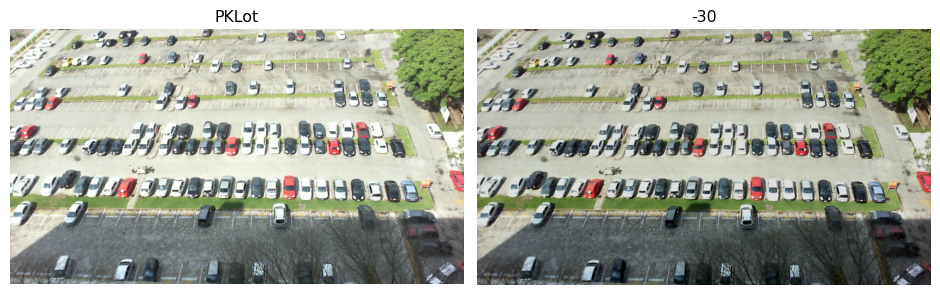

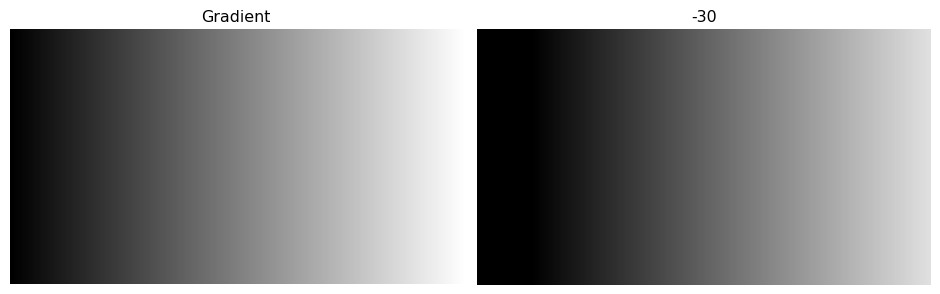

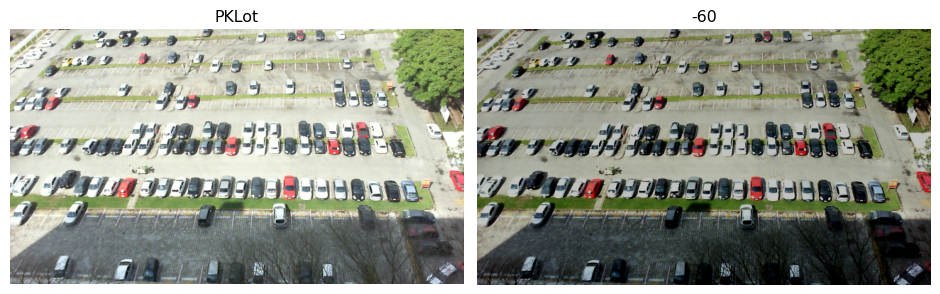

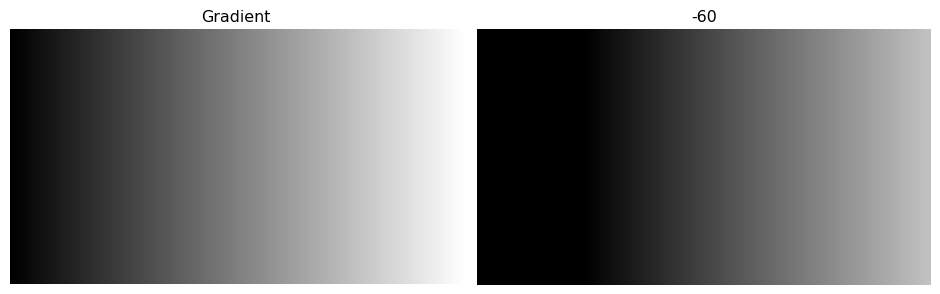

In [9]:
t2=ensure_dir(OUT/"Task 2"); notes=["Subtraction.\n"]
for c in (10,30,60):
    a=cv2.subtract(work,np.full_like(work,c)); b=cv2.subtract(np_img,np.full_like(np_img,c))
    show_pair(work,a,"PKLot",f"-{c}",t2/f"parking_sub_{c}.png")
    show_pair(np_img,b,"Gradient",f"-{c}",t2/f"numpy_sub_{c}.png")
    save_bgr(t2/f"parking_sub_{c}.jpg",a); save_bgr(t2/f"numpy_sub_{c}.jpg",b)
    notes.append(f"c={c}: zero%={100*np.mean(a==0):.1f}")
(t2/"observation.txt").write_text("\n".join(notes)+"\n",encoding="utf-8")


## Task 3 — Multiplication


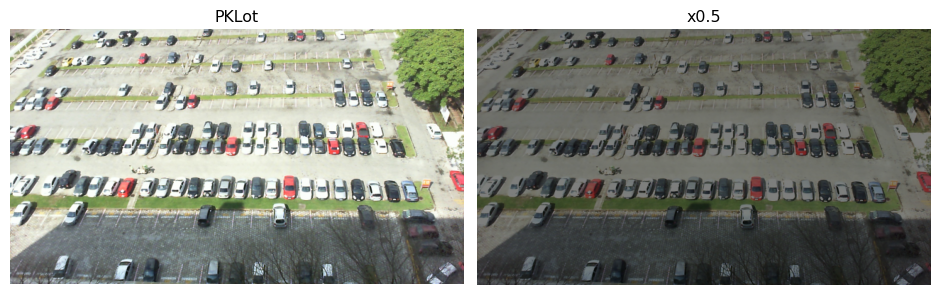

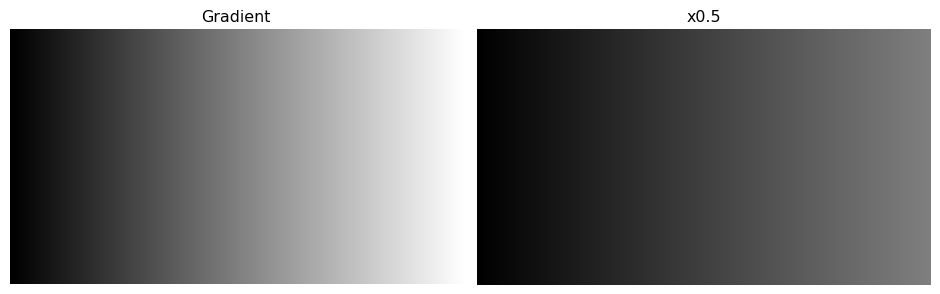

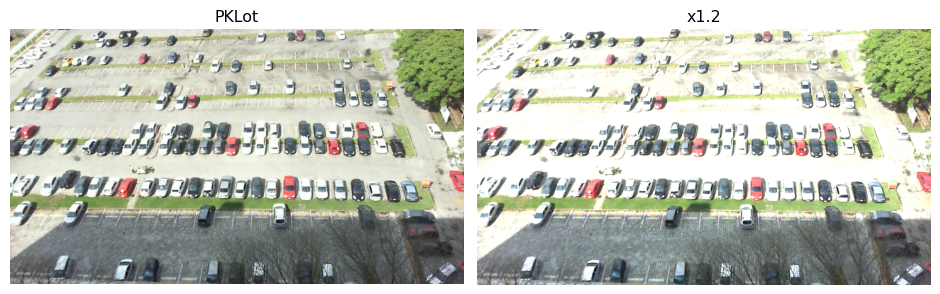

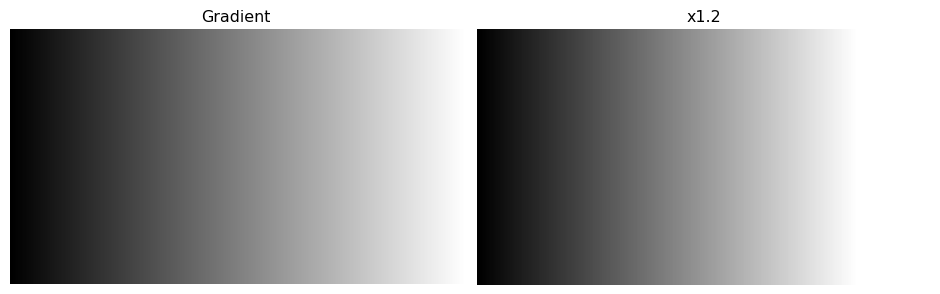

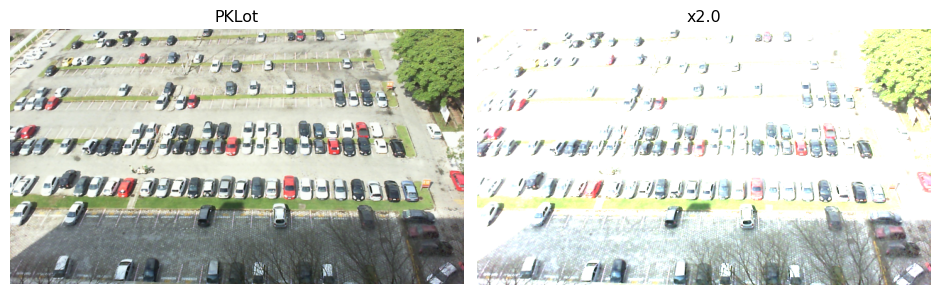

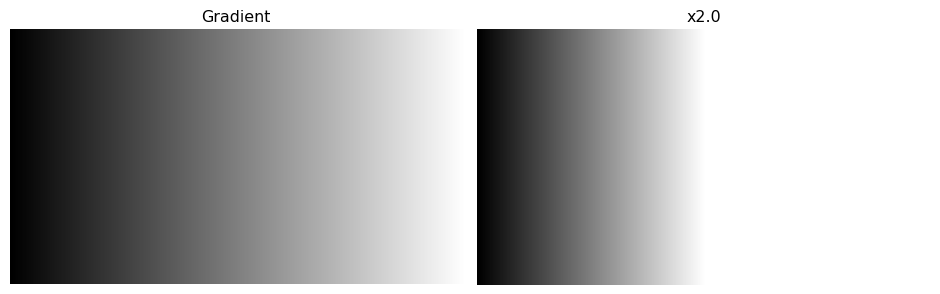

In [11]:
t3=ensure_dir(OUT/"Task 3"); notes=["Multiplication.\n"]
for f in (0.5,1.2,2.0):
    a=np.clip(work.astype(np.float32)*f,0,255).astype(np.uint8)
    b=np.clip(np_img.astype(np.float32)*f,0,255).astype(np.uint8)
    show_pair(work,a,"PKLot",f"x{f}",t3/f"parking_mul_{f}.png")
    show_pair(np_img,b,"Gradient",f"x{f}",t3/f"numpy_mul_{f}.png")
    save_bgr(t3/f"parking_mul_{f}.jpg",a); save_bgr(t3/f"numpy_mul_{f}.jpg",b)
(t3/"observation.txt").write_text("\n".join(notes)+"\n",encoding="utf-8")


## Task 4 — Division


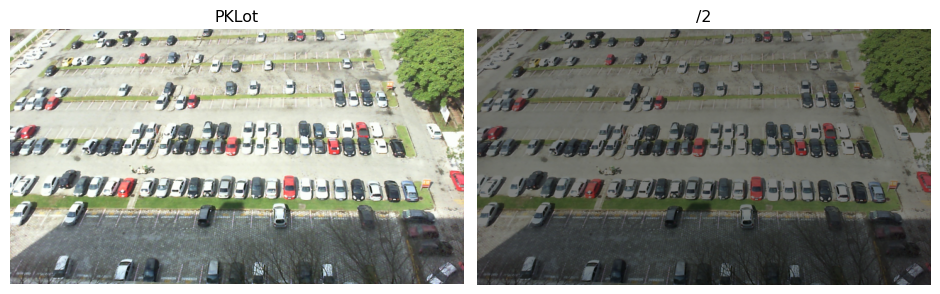

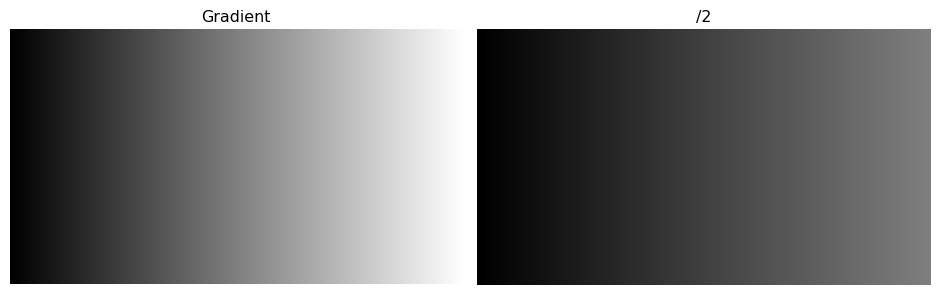

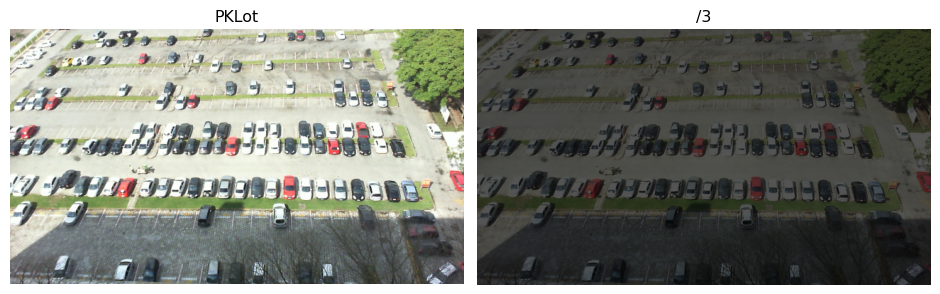

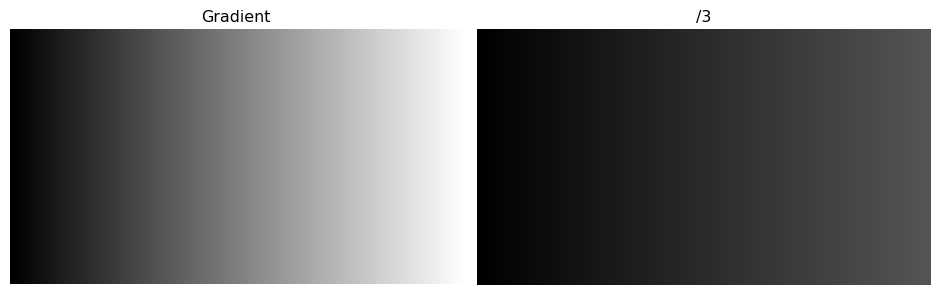

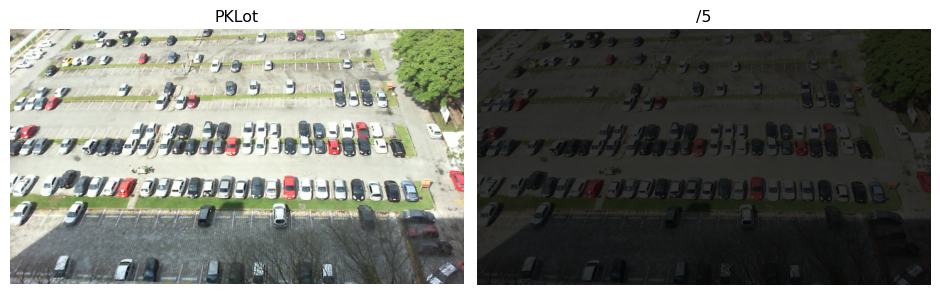

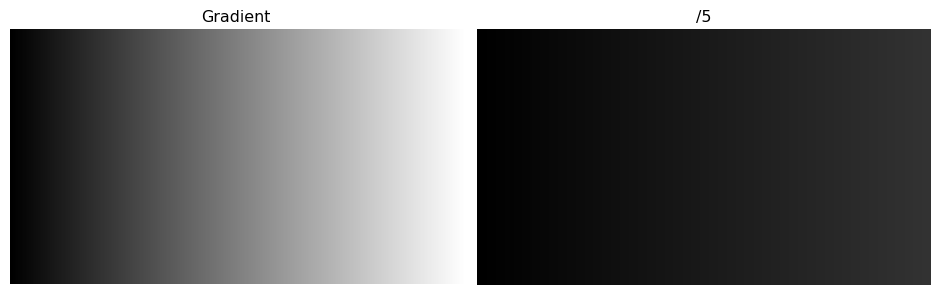

In [13]:
t4=ensure_dir(OUT/"Task 4")
for d in (2,3,5):
    a=(work.astype(np.float32)/d).clip(0,255).astype(np.uint8)
    b=(np_img.astype(np.float32)/d).clip(0,255).astype(np.uint8)
    show_pair(work,a,"PKLot",f"/{d}",t4/f"parking_div_{d}.png")
    show_pair(np_img,b,"Gradient",f"/{d}",t4/f"numpy_div_{d}.png")
    save_bgr(t4/f"parking_div_{d}.jpg",a); save_bgr(t4/f"numpy_div_{d}.jpg",b)
(t4/"observation.txt").write_text("Division reduces intensity.\n",encoding="utf-8")


## Task 5 — Negative


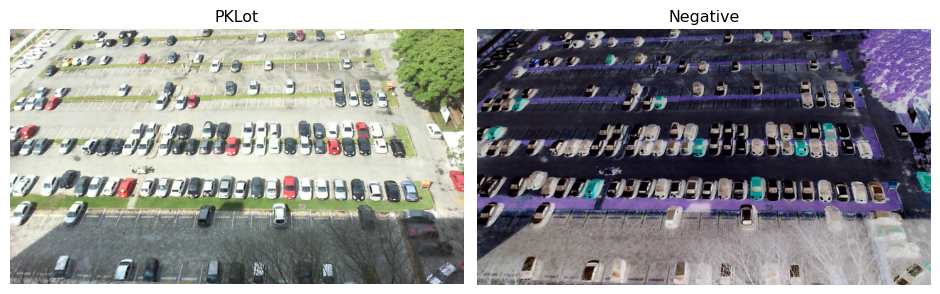

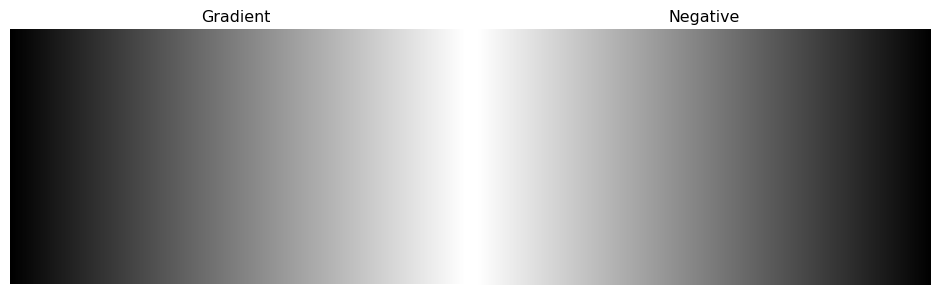

In [15]:
t5=ensure_dir(OUT/"Task 5"); a,b=255-work,255-np_img
show_pair(work,a,"PKLot","Negative",t5/"parking_negative.png")
show_pair(np_img,b,"Gradient","Negative",t5/"numpy_negative.png")
save_bgr(t5/"parking_negative.jpg",a); save_bgr(t5/"numpy_negative.jpg",b)
(t5/"observation.txt").write_text("g=255-f\n",encoding="utf-8")


## Task 5b — Count empty parking slots (REAL PKLot)


PKLot REAL dataset
Empty slot %=55.55
Otsu=166.0 thresh=166
Bright=empty asphalt; dark=occupied cars.



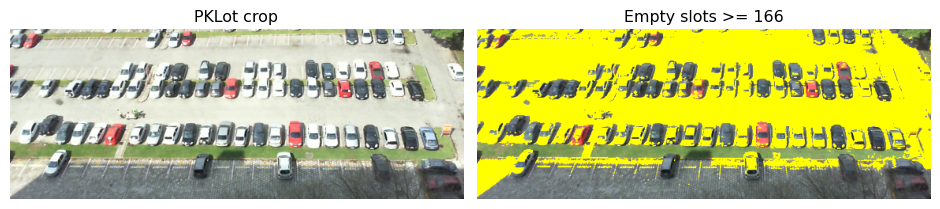

In [17]:
t5b=ensure_dir(OUT/"Task 5 Count White Spaces")
gray=cv2.cvtColor(work,cv2.COLOR_BGR2GRAY)
y1,y2=int(h*0.25),int(h*0.85); x1,x2=int(w*0.05),int(w*0.95)
crop,cg=work[y1:y2,x1:x2],gray[y1:y2,x1:x2]
otsu,_=cv2.threshold(cg,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
thresh=max(int(otsu),140); empty=cg>=thresh; pct=100*empty.mean()
vis=crop.copy(); vis[empty]=(0,255,255)
show_pair(crop,vis,"PKLot crop",f"Empty slots >= {thresh}",t5b/"white_space_analysis.png")
save_bgr(t5b/"white_mask.jpg",(empty.astype(np.uint8)*255))
stats=f"PKLot REAL dataset\nEmpty slot %={pct:.2f}\nOtsu={otsu} thresh={thresh}\nBright=empty asphalt; dark=occupied cars.\n"
(t5b/"white_space_stats.txt").write_text(stats,encoding="utf-8"); print(stats)


## Task 6 — Bounding boxes on REAL forest → highlighted_forest_area.jpg


Lab 3 done -> C:\Users\hashi\OneDrive - Higher Education Commission\6 SEM\Dip lab\Output\Lab 3


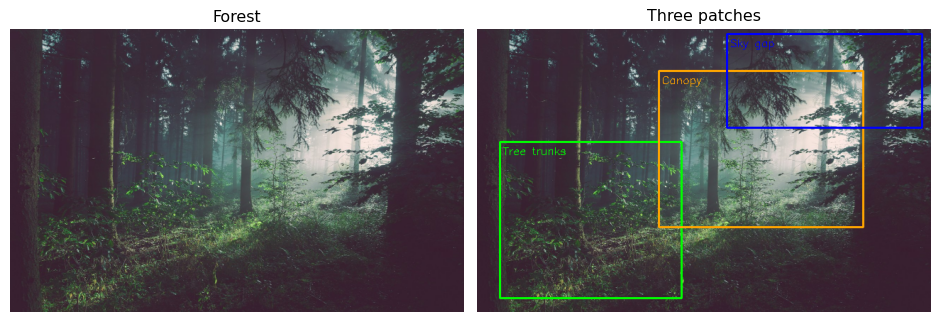

In [19]:
t6=ensure_dir(OUT/"Task 6")
fw=cv2.resize(forest_img,(640,400)); fh,fww=fw.shape[:2]; boxed=fw.copy()
boxes=[(int(fww*0.05),int(fh*0.40),int(fww*0.45),int(fh*0.95)),
       (int(fww*0.40),int(fh*0.15),int(fww*0.85),int(fh*0.70)),
       (int(fww*0.55),int(fh*0.02),int(fww*0.98),int(fh*0.35))]
for (x1,y1,x2,y2),c,l in zip(boxes,[(0,255,0),(0,165,255),(255,0,0)],["Tree trunks","Canopy","Sky gap"]):
    cv2.rectangle(boxed,(x1,y1),(x2,y2),c,2); cv2.putText(boxed,l,(x1+4,y1+18),cv2.FONT_HERSHEY_SIMPLEX,0.5,c,1)
save_bgr(t6/"highlighted_forest_area.jpg", boxed)
show_pair(fw,boxed,"Forest","Three patches",t6/"bounding_boxes.png")
print("Lab 3 done ->", OUT)
